# Сходство, поиск и группировка текстов

Векторное представление текста используется для трёх практических операций: измерения близости сообщений, поиска обращений по запросу и группировки похожих обращений. Исходные сообщения — учебный набор обращений в поддержку. Векторизация обучается только на части `train`; метки тем служат лишь для внешней проверки уже построенных групп.

У поиска и группировки разные вопросы. Поиск получает конкретный запрос и выдаёт ранжированный список документов. Группировка получает весь набор векторов и распределяет их без подсказки правильных тем. Число кластера — внутренний номер алгоритма, а не название темы. 

Точные дубли обращений удаляются по `case_id`: повторные экспортные строки не становятся дополнительными наблюдениями. Нормализация текста применяется той же функцией, что и ранее. Фрагмент `reviews.txt` в конце показывает, что кластеры возможны и без содержательных тем.

## 1. Косинусное сходство: геометрия и корпус

Вектор документа задаёт направление в пространстве признаков. Скалярное произведение складывает произведения соответствующих координат; деление на длины двух векторов даёт косинус угла. Для неотрицательных TF–IDF-векторов значение лежит от нуля до единицы: ноль означает отсутствие общей ненулевой координаты, единица — одинаковое направление.  После преобразований с отрицательными координатами косинус может лежать в диапазоне от −1 до 1.

**Импорты и согласованность обращений**

Таблица загружается из соседней папки `data`; для одинаковых `case_id` проверяется согласованность текста и разметки. После удаления повторных экспортных строк остаётся 2178 обращений, из них 1452 в `train`. Остальные части пока не входят в корпус поиска и кластеризации. Если проверка согласованности не пройдёт, автоматически выбирать одну из противоречивых строк нельзя.

In [1]:
# Шаг М3.04.01 — Импорты и согласованность обращений
from pathlib import Path
import html, re, unicodedata
from itertools import islice
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity
from threadpoolctl import threadpool_limits

plt.rcParams['font.family'] = 'DejaVu Sans'
data_path = Path('data/support_messages.csv')
assert data_path.exists(), f'Не найден файл {data_path.resolve()}'
raw = pd.read_csv(data_path)
columns = ['family_id', 'text', 'topic', 'split']
conflicts = raw.groupby('case_id')[columns].nunique(dropna=False).gt(1).any(axis=1)
assert not conflicts.any(), 'Есть противоречивые строки с одинаковым case_id'
unique = raw.drop_duplicates('case_id').reset_index(drop=True)
print('Строк экспорта:', len(raw), '| уникальных обращений:', len(unique))
print('Учебных обращений:', int(unique['split'].eq('train').sum()))

Строк экспорта: 2412 | уникальных обращений: 2178
Учебных обращений: 1452


**Единая нормализация и учебный корпус**

Применяется единая нормализация: HTML-сущности раскрываются, теги удаляются, цифры заменяются словом «номер», регистр и пробелы приводятся к единому виду. Выводятся первые записи и размер корпуса. Метки тем сохраняются в таблице только для последующей диагностики.

In [2]:
# Шаг М3.04.02 — Единая нормализация и учебный корпус
def normalize_text(text):
    text = unicodedata.normalize('NFKC', html.unescape(str(text)))
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'\d+', ' номер ', text)
    return ' '.join(text.casefold().split())

train = unique.loc[unique['split'].eq('train')].copy().reset_index(drop=True)
train['clean_text'] = train['text'].map(normalize_text)
assert len(train) == 1452 and train['clean_text'].ne('').all()
print(train[['case_id', 'clean_text']].head(3).to_string(index=False))

        case_id                                                                                                                   clean_text
доставка_00_000 подскажите, пожалуйста: курьер перенёс доставку, когда привезут заказ. заказ no номер . нужна информация по моему обращению.
доставка_00_001                                 здравствуйте. курьер перенёс доставку, когда привезут заказ. заказ no номер . жду уточнения.
доставка_00_002                         курьер перенёс доставку, когда привезут заказ. заказ no номер . нужна информация по моему обращению.


**Скалярное произведение и нормы: ручной пример**

Используются три двумерных вектора. Первые два имеют общую первую координату, третий направлен по другой оси. Скалярное произведение, нормы и косинус вычисляются вручную и проверяются библиотечной функцией. Угол нужен для геометрического смысла: близкие направления дают большой косинус даже при разной длине векторов.

In [3]:
# Шаг М3.04.03 — Ручной пример: произведение и нормы
a = np.array([3.0, 4.0])
b = np.array([6.0, 0.0])
c = np.array([0.0, 5.0])
dot_ab = float(a @ b)
norm_a, norm_b = np.linalg.norm(a), np.linalg.norm(b)
manual_cos = dot_ab / (norm_a * norm_b)
angle = np.degrees(np.arccos(np.clip(manual_cos, -1, 1)))
print(f'a·b={dot_ab:.1f}; ||a||={norm_a:.1f}; ||b||={norm_b:.1f}')
print(f'cos(a,b)={manual_cos:.3f}; угол={angle:.1f}°')
print('cos(a,c)=', round(float(cosine_similarity([a], [c])[0, 0]), 3))

a·b=18.0; ||a||=5.0; ||b||=6.0
cos(a,b)=0.600; угол=53.1°
cos(a,c)= 0.8


**Векторы и угол на плоскости**

Небольшой рисунок показывает три направления. Он помогает связать формулу с геометрией, но двумерная плоскость здесь только игрушечный пример. Реальные текстовые векторы содержат гораздо больше координат. При нулевой длине делить на нормы нельзя; такие запросы отдельно обрабатываются в разделе поиска.

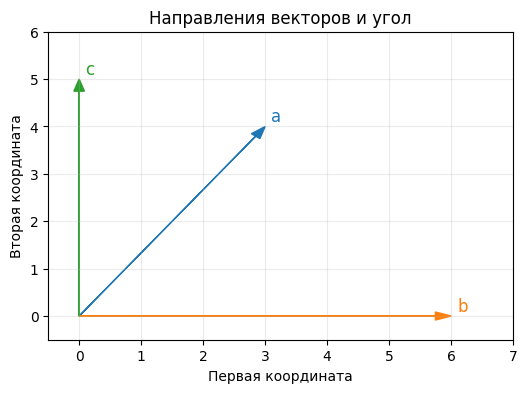

In [4]:
# Шаг М3.04.04 — Векторы и угол на плоскости
fig, ax = plt.subplots(figsize=(6, 4))
for vec, label, color in [(a, 'a', 'tab:blue'), (b, 'b', 'tab:orange'), (c, 'c', 'tab:green')]:
    ax.arrow(0, 0, vec[0], vec[1], head_width=.17, length_includes_head=True, color=color)
    ax.text(vec[0] + .1, vec[1] + .1, label, color=color, fontsize=12)
ax.set(xlim=(-.5, 7), ylim=(-.5, 6), xlabel='Первая координата', ylabel='Вторая координата', title='Направления векторов и угол')
ax.grid(alpha=.25)
plt.show()

**TF–IDF для обращений**

Один TF–IDF-векторизатор обучается на `train` и применяется к документам и будущим запросам. Матрица остаётся разреженной: плотный массив для 1452 строк не создаётся. В этой реализации строки уже нормированы по длине L2, поэтому для них скалярное произведение совпадает с косинусным сходством.

In [5]:
# Шаг М3.04.05 — TF–IDF для обращений
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=.90, norm='l2')
X = vectorizer.fit_transform(train['clean_text'])
assert X.shape[0] == len(train)
print('Размер матрицы:', X.shape, '| ненулевых значений:', X.nnz)
print('Формат:', type(X).__name__, '| нормы первых строк:', np.round(np.sqrt(X[:3].multiply(X[:3]).sum(axis=1)).A1, 3))

Размер матрицы: (1452, 719) | ненулевых значений: 30827
Формат: csr_matrix | нормы первых строк: [1. 1. 1.]


**Сходство восьми документов**

Для наглядности строится матрица только для восьми обращений — это допустимый маленький квадрат 8×8. Диагональ равна единице: документ сравнивается сам с собой. Вне диагонали заметны пары с общими формулировками.

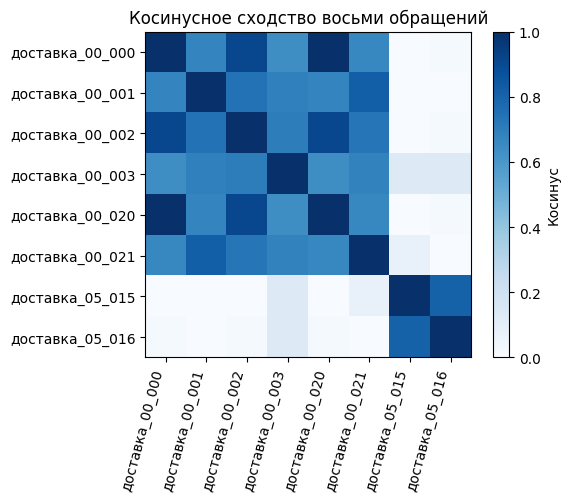

In [6]:
# Шаг М3.04.06 — Сходство восьми документов
small_ids = [0, 1, 2, 3, 20, 21, 240, 241]
small_sim = cosine_similarity(X[small_ids])
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(small_sim, vmin=0, vmax=1, cmap='Blues')
ax.set_xticks(range(8), [train.loc[i, 'case_id'] for i in small_ids], rotation=75, ha='right')
ax.set_yticks(range(8), [train.loc[i, 'case_id'] for i in small_ids])
ax.set_title('Косинусное сходство восьми обращений')
fig.colorbar(image, ax=ax, label='Косинус')
plt.tight_layout()
plt.show()

Получена разреженная матрица; смысл косинуса проверен на ручном примере и восьми обращениях. Далее та же мера используется для упорядочивания документов относительно запроса.

## 2. Поиск и близкие обращения

Поисковый запрос проходит через нормализацию и `transform` уже обученного векторизатора. Новый `fit` менять словарь не должен: иначе координаты запроса и документов перестанут совпадать. Ранжируются только положительные оценки; при равенстве действует стабильный порядок по `case_id`. Пустой запрос или запрос вне словаря даёт пустую выдачу. Нулевое совпадение означает отсутствие лексического сигнала в данной модели, а не доказательство смысловой несвязанности.

**Функция поиска с устойчивым порядком**

Функция возвращает идентификатор, оценку и текст, а также нормализованный запрос. Оценки считаются как один вектор на весь корпус, без матрицы «каждый с каждым». При точном равенстве оценок первым идёт лексикографически меньший `case_id`; это обеспечивает воспроизводимость. Вектор без ненулевых координат и выдача с нулевыми оценками обрабатываются явно.

In [7]:
# Шаг М3.04.07 — Функция поиска с устойчивым порядком
def search(query, top_k=5):
    clean_query = normalize_text(query)
    if not clean_query or top_k <= 0:
        return clean_query, pd.DataFrame(columns=['case_id', 'score', 'clean_text'])
    q = vectorizer.transform([clean_query])
    if q.nnz == 0:
        return clean_query, pd.DataFrame(columns=['case_id', 'score', 'clean_text'])
    scores = (X @ q.T).toarray().ravel()
    candidates = np.flatnonzero(scores > 0)
    ordered = sorted(candidates, key=lambda i: (-scores[i], train.loc[i, 'case_id']))[:top_k]
    result = train.loc[ordered, ['case_id', 'clean_text']].copy()
    result.insert(1, 'score', np.round(scores[ordered], 4))
    return clean_query, result.reset_index(drop=True)

print(search('курьер перенёс доставку', 3)[1].to_string(index=False, max_colwidth=90))

        case_id  score                                                                                 clean_text
доставка_00_005 0.6751                            курьер перенёс доставку, когда привезут заказ. заказ no номер .
доставка_00_043 0.6212         курьер перенёс доставку, когда привезут заказ. заказ no номер . спасибо за помощь.
доставка_00_019 0.6159 курьер перенёс доставку, когда привезут заказ. заказ no номер . прошу ответить в сообще...


**Несколько задач для одного индекса**

Один индекс проверяется на разных формулировках: доставка, двойное списание и возврат. Для каждого запроса выводятся оценки и тексты. Слова «заказ» и «номер» встречаются широко; высокое место заслуживает проверки по конкретной ситуации. Результаты для каждого запроса выводятся отдельно, чтобы не смешивать ранги разных списков.

In [8]:
# Шаг М3.04.08 — Несколько задач для одного индекса
queries = ['курьер перенёс доставку', 'карта списала деньги дважды', 'как оформить возврат покупки']
for query in queries:
    clean_query, found = search(query, 3)
    print('\nЗапрос:', clean_query)
    print(found.to_string(index=False, max_colwidth=92))


Запрос: курьер перенёс доставку
        case_id  score                                                                                  clean_text
доставка_00_005 0.6751                             курьер перенёс доставку, когда привезут заказ. заказ no номер .
доставка_00_043 0.6212          курьер перенёс доставку, когда привезут заказ. заказ no номер . спасибо за помощь.
доставка_00_019 0.6159 курьер перенёс доставку, когда привезут заказ. заказ no номер . прошу ответить в сообщении.



Запрос: карта списала деньги дважды
      case_id  score                                                                                  clean_text
оплата_00_015 0.7436                             карта списала деньги дважды при оплате заказа. заказ no номер .
оплата_00_005 0.6993          карта списала деньги дважды при оплате заказа. заказ no номер . спасибо за помощь.
оплата_00_026 0.6947 карта списала деньги дважды при оплате заказа. заказ no номер . прошу ответить в сообщении.

Запрос: как оформить возврат покупки
       case_id  score                                                                                  clean_text
возврат_00_009 0.6521     как оформить возврат покупки и получить деньги обратно. заказ no номер . жду уточнения.
возврат_00_018 0.6438 как оформить возврат покупки и получить деньги обратно. заказ no номер . спасибо за помощь.
возврат_00_011 0.6407      здравствуйте. как оформить возврат покупки и получить деньги обратно. заказ no номер .


**Пустой запрос и слова вне словаря**

Пустой запрос и выдуманное слово проверяют два разных случая. Первый не содержит текста, второй содержит символы, но не даёт ни одного признака в обученном словаре. Оба должны вернуть пустую таблицу, а не произвольную пятёрку документов с нулевой оценкой. Это часть корректного пользовательского поведения поисковой функции.

In [9]:
# Шаг М3.04.09 — Пустой запрос и слова вне словаря
for query in ['', '   ', 'сверхфотоноквантность']:
    clean_query, found = search(query)
    print(f'Запрос {query!r}: нормализованное значение {clean_query!r}, найдено {len(found)}')

Запрос '': нормализованное значение '', найдено 0
Запрос '   ': нормализованное значение '', найдено 0
Запрос 'сверхфотоноквантность': нормализованное значение 'сверхфотоноквантность', найдено 0


**Нет лексического пересечения**

Даже непустой запрос может не иметь общей координаты ни с одним документом. Для специального запроса выводится число положительных совпадений. Здесь нельзя подменять ноль «семантической близостью»: TF–IDF не умеет самостоятельно распознавать синонимы, которых нет в общих признаках. Значение косинуса описывает именно построенные признаки.

In [10]:
# Шаг М3.04.10 — Нет лексического пересечения
unmatched = 'фотосинтез галактики'
q_unmatched = vectorizer.transform([normalize_text(unmatched)])
scores_unmatched = (X @ q_unmatched.T).toarray().ravel()
print('Ненулевых признаков запроса:', q_unmatched.nnz)
print('Положительных совпадений с документами:', int((scores_unmatched > 0).sum()))
print('Выдача:', len(search(unmatched)[1]))

Ненулевых признаков запроса: 0
Положительных совпадений с документами: 0
Выдача: 0


**Близкие документы для выбранного обращения**

Поиск можно начать и от уже имеющегося документа: его вектор сравнивается с остальным корпусом. Исходное обращение исключается, иначе оно займёт первое место с косинусом 1. Это способ найти похожие случаи или кандидатов в почти дубли; автоматическое решение по клиенту из списка не следует. Выводятся несколько соседей с оценками и текстом.

In [11]:
# Шаг М3.04.11 — Близкие документы для выбранного обращения
anchor = 0
anchor_scores = (X @ X[anchor].T).toarray().ravel()
neighbors = sorted((i for i in range(len(train)) if i != anchor and anchor_scores[i] > 0),
                   key=lambda i: (-anchor_scores[i], train.loc[i, 'case_id']))[:5]
print('Исходное обращение:', train.loc[anchor, 'case_id'], train.loc[anchor, 'clean_text'])
for i in neighbors:
    print(f"{train.loc[i, 'case_id']} | {anchor_scores[i]:.3f} | {train.loc[i, 'clean_text']}")

Исходное обращение: доставка_00_000 подскажите, пожалуйста: курьер перенёс доставку, когда привезут заказ. заказ no номер . нужна информация по моему обращению.
доставка_00_020 | 1.000 | подскажите, пожалуйста: курьер перенёс доставку, когда привезут заказ. заказ no номер . нужна информация по моему обращению.
доставка_00_002 | 0.907 | курьер перенёс доставку, когда привезут заказ. заказ no номер . нужна информация по моему обращению.
доставка_00_004 | 0.907 | курьер перенёс доставку, когда привезут заказ. заказ no номер . нужна информация по моему обращению.
доставка_00_022 | 0.907 | курьер перенёс доставку, когда привезут заказ. заказ no номер . нужна информация по моему обращению.
доставка_00_008 | 0.837 | подскажите, пожалуйста: курьер перенёс доставку, когда привезут заказ. заказ no номер . спасибо за помощь.


**Учебные пары для настройки порога дублей**

Валидационная часть не участвовала в обучении TF–IDF. Используется небольшой фиксированный набор пар: несколько из одного семейства формулировок и столько же из разных. `family_id` здесь используется только как учебная внешняя проверка порога, а не как признак. Сходство вычисляется отдельно для каждой заданной пары; полная матрица «валидация на валидацию» не создаётся.

In [12]:
# Шаг М3.04.12 — Учебные пары для настройки порога дублей
validation = unique.loc[unique['split'].eq('validation')].copy().reset_index(drop=True)
validation['clean_text'] = validation['text'].map(normalize_text)
V = vectorizer.transform(validation['clean_text'])
groups = [g.index.tolist() for _, g in validation.groupby('family_id', sort=True)]
same_pairs = [(g[0], g[1]) for g in groups[:12]]
different_pairs = [(groups[i][0], groups[(i + 1) % len(groups)][0]) for i in range(12)]
pairs = same_pairs + different_pairs
pair_labels = np.array([1] * len(same_pairs) + [0] * len(different_pairs))
pair_scores = np.array([float(V[i].multiply(V[j]).sum()) for i, j in pairs])
print('Пар:', len(pairs), '| одного семейства:', int(pair_labels.sum()))
print(pd.DataFrame({'тип': np.where(pair_labels, 'одно семейство', 'разные семейства'),
                    'сходство': np.round(pair_scores, 3)}).groupby('тип').agg(['min', 'median', 'max']).round(3))

Пар: 24 | одного семейства: 12
                 сходство              
                      min median    max
тип                                    
одно семейство      0.339  0.654  1.000
разные семейства    0.000  0.000  0.307


**Порог на валидации и его предел**

Несколько заранее заданных порогов сравниваются по F1 на маленьком наборе учебных пар. Таблица также показывает precision и recall, чтобы выбор не скрывал компромисс между ложными совпадениями и пропусками. Выбранное число применимо только как иллюстрация для этих данных и этой схемы пар; перед реальным использованием нужны независимые размеченные примеры и цена ошибок.

In [13]:
# Шаг М3.04.13 — Порог на валидации и его предел
threshold_rows = []
for threshold in [0.40, 0.55, 0.70, 0.85, 0.95]:
    predicted = pair_scores >= threshold
    tp = int((predicted & (pair_labels == 1)).sum())
    fp = int((predicted & (pair_labels == 0)).sum())
    fn = int((~predicted & (pair_labels == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    threshold_rows.append((threshold, precision, recall, f1))
threshold_table = pd.DataFrame(threshold_rows, columns=['порог', 'precision', 'recall', 'F1'])
chosen_threshold = max(threshold_rows, key=lambda row: (row[3], row[1], row[0]))[0]
print(threshold_table.round(3).to_string(index=False))
print('Учебный порог:', chosen_threshold)

 порог  precision  recall    F1
  0.40        1.0   0.917 0.957
  0.55        1.0   0.583 0.737
  0.70        1.0   0.333 0.500
  0.85        1.0   0.083 0.154
  0.95        1.0   0.083 0.154
Учебный порог: 0.4


**Кандидаты в почти дубли**

Выбранный порог применяется к соседям одного учебного обращения. Условие создаёт список кандидатов, а не окончательную метку дубля. Сравнение остаётся «один документ против корпуса». При равных оценках сохраняется тот же порядок по идентификатору, что и в поиске. Вывод ограничен несколькими строками для удобства чтения.

In [14]:
# Шаг М3.04.14 — Кандидаты в почти дубли
near = sorted((i for i in range(len(train)) if i != anchor and anchor_scores[i] >= chosen_threshold),
              key=lambda i: (-anchor_scores[i], train.loc[i, 'case_id']))
print('Кандидатов для', train.loc[anchor, 'case_id'], ':', len(near))
for i in near[:5]:
    print(f"{train.loc[i, 'case_id']} | {anchor_scores[i]:.3f} | {train.loc[i, 'clean_text']}")

Кандидатов для доставка_00_000 : 44
доставка_00_020 | 1.000 | подскажите, пожалуйста: курьер перенёс доставку, когда привезут заказ. заказ no номер . нужна информация по моему обращению.
доставка_00_002 | 0.907 | курьер перенёс доставку, когда привезут заказ. заказ no номер . нужна информация по моему обращению.
доставка_00_004 | 0.907 | курьер перенёс доставку, когда привезут заказ. заказ no номер . нужна информация по моему обращению.
доставка_00_022 | 0.907 | курьер перенёс доставку, когда привезут заказ. заказ no номер . нужна информация по моему обращению.
доставка_00_008 | 0.837 | подскажите, пожалуйста: курьер перенёс доставку, когда привезут заказ. заказ no номер . спасибо за помощь.


Поиск возвращает ранжированный список, а проверенный порог выделяет лишь кандидатов в почти дубли. Далее задаются критерии релевантности нескольких запросов и измеряется качество верхней части выдачи.

## 3. Проверка качества поиска

Ранжирование оценивается только на полностью размеченном учебном пуле. Для четырёх конкретных запросов заранее выбраны по три релевантных обращения; объединение этих списков даёт 12 документов. Внутри пула остальные девять документов для каждого запроса считаются нерелевантными по сформулированному критерию. Обращения основного корпуса вне пула не размечены: их нельзя считать промахами при вычислении Precision@5 или MRR.

**Запросы и релевантные документы**

Для каждого запроса задана конкретная проблема и три `case_id`, а не широкая тема. Списки объединяются в полностью размеченный пул из 12 документов до вычисления метрик. Функция ранжирует только этот пул, используя уже обученный векторизатор и строки исходной матрицы; нового `fit` нет.

In [15]:
# Шаг М3.04.15 — Фиксируем запросы и релевантные документы
qrels = {
    'курьер перенёс доставку': {'доставка_00_000', 'доставка_00_001', 'доставка_00_002'},
    'карта списала деньги дважды': {'оплата_00_000', 'оплата_00_001', 'оплата_00_002'},
    'как оформить возврат покупки': {'возврат_00_000', 'возврат_00_001', 'возврат_00_002'},
    'у товара сломана кнопка включения': {'товар_00_000', 'товар_00_001', 'товар_00_002'},
}
criteria = {
    'курьер перенёс доставку': 'перенос доставки курьером',
    'карта списала деньги дважды': 'двойное списание при оплате',
    'как оформить возврат покупки': 'оформление возврата покупки',
    'у товара сломана кнопка включения': 'неисправная кнопка товара',
}
pool_ids = sorted(set().union(*qrels.values()))
positions = train.set_index('case_id').index.get_indexer(pool_ids)
assert len(pool_ids) == 12 and (positions >= 0).all()
pool = train.iloc[positions].reset_index(drop=True)
pool_X = X[positions]

def search_labeled_pool(query, top_k=5):
    clean_query = normalize_text(query)
    if not clean_query or top_k <= 0:
        return pd.DataFrame(columns=['case_id', 'score', 'clean_text'])
    q = vectorizer.transform([clean_query])
    if q.nnz == 0:
        return pd.DataFrame(columns=['case_id', 'score', 'clean_text'])
    scores = (pool_X @ q.T).toarray().ravel()
    ordered = sorted(range(len(pool)), key=lambda i: (-scores[i], pool.loc[i, 'case_id']))[:top_k]
    result = pool.loc[ordered, ['case_id', 'clean_text']].copy()
    result.insert(1, 'score', np.round(scores[ordered], 4))
    return result.reset_index(drop=True)

print('Размер полностью размеченного пула:', len(pool))
for query, ids in qrels.items():
    print(query, '| критерий:', criteria[query], '| релевантных:', len(ids))

Размер полностью размеченного пула: 12
курьер перенёс доставку | критерий: перенос доставки курьером | релевантных: 3
карта списала деньги дважды | критерий: двойное списание при оплате | релевантных: 3
как оформить возврат покупки | критерий: оформление возврата покупки | релевантных: 3
у товара сломана кнопка включения | критерий: неисправная кнопка товара | релевантных: 3


**Precision@k внутри размеченного пула**

Precision@5 — доля релевантных среди первых пяти документов пула. Для одного запроса показана верхняя пятёрка с заранее заданными пометками. Пул содержит 12 полностью размеченных обращений, поэтому каждое место выдачи имеет известный статус. Эта метрика описывает только поиск внутри пула, а не качество выдачи по всем 1452 обращениям.

In [16]:
# Шаг М3.04.16 — Precision@k для верхней части списка
example_query = 'курьер перенёс доставку'
example_found = search_labeled_pool(example_query, 5)
example_found['релевантен'] = example_found['case_id'].isin(qrels[example_query])
p_at_5 = example_found['релевантен'].sum() / 5
print('Размер размеченного пула:', len(pool))
print(example_found[['case_id', 'score', 'релевантен']].to_string(index=False))
print(f'Precision@5 внутри пула = {p_at_5:.3f}')

Размер размеченного пула: 12
        case_id  score  релевантен
доставка_00_002 0.5872        True
доставка_00_001 0.5766        True
доставка_00_000 0.5328        True
 возврат_00_000 0.0000       False
 возврат_00_001 0.0000       False
Precision@5 внутри пула = 0.600


**MRR и Precision@5 на четырёх запросах**

Для каждого запроса ранжируются все 12 документов пула. Reciprocal rank равен `1/rank` первого релевантного документа, MRR — среднее по четырём запросам. Рядом вычисляется Precision@5. Числа не относятся к общей выдаче по 1452 строкам: документы вне пула не размечены и в расчёте не участвуют.

In [17]:
# Шаг М3.04.17 — MRR и средняя точность выдачи
evaluation = []
for query, relevant in qrels.items():
    found = search_labeled_pool(query, len(pool))
    ids = found['case_id'].tolist()
    hits5 = sum(case_id in relevant for case_id in ids[:5])
    first_rank = next((rank for rank, case_id in enumerate(ids, 1) if case_id in relevant), None)
    evaluation.append((query, hits5 / 5, 1 / first_rank if first_rank else 0.0, first_rank))
eval_table = pd.DataFrame(evaluation, columns=['запрос', 'Precision@5', 'RR', 'первый релевантный ранг'])
print('Размер размеченного пула:', len(pool))
print(eval_table.to_string(index=False))
print('Средний Precision@5 внутри пула:', round(eval_table['Precision@5'].mean(), 3))
print('MRR внутри пула:', round(eval_table['RR'].mean(), 3))

Размер размеченного пула: 12
                           запрос  Precision@5  RR  первый релевантный ранг
          курьер перенёс доставку          0.6 1.0                        1
      карта списала деньги дважды          0.6 1.0                        1
     как оформить возврат покупки          0.6 1.0                        1
у товара сломана кнопка включения          0.6 1.0                        1
Средний Precision@5 внутри пула: 0.6
MRR внутри пула: 1.0


**Общая выдача и неразмеченные документы**

Отдельно показан общий поиск по 1452 обращениям. Для документов из пула известна релевантность данному запросу; для остальных статус «не размечен», даже если они описывают ту же проблему. Примеры доступны для чтения; Precision@5 и MRR по общей выдаче не вычисляются.

In [18]:
# Шаг М3.04.18 — Разбор ограничений ручного эталона
inspection_query = 'карта списала деньги дважды'
_, inspection = search(inspection_query, 7)
inspection['статус'] = [
    'релевантен в пуле' if case_id in qrels[inspection_query]
    else 'нерелевантен в пуле' if case_id in pool_ids
    else 'не размечен'
    for case_id in inspection['case_id']
]
print('Общий корпус:', len(train), '| размеченный пул:', len(pool))
print(inspection.to_string(index=False, max_colwidth=100))

Общий корпус: 1452 | размеченный пул: 12
      case_id  score                                                                                  clean_text      статус
оплата_00_015 0.7436                             карта списала деньги дважды при оплате заказа. заказ no номер . не размечен
оплата_00_005 0.6993          карта списала деньги дважды при оплате заказа. заказ no номер . спасибо за помощь. не размечен
оплата_00_026 0.6947 карта списала деньги дважды при оплате заказа. заказ no номер . прошу ответить в сообщении. не размечен
оплата_00_006 0.6934               здравствуйте. карта списала деньги дважды при оплате заказа. заказ no номер . не размечен
оплата_00_009 0.6934               здравствуйте. карта списала деньги дважды при оплате заказа. заказ no номер . не размечен
оплата_00_010 0.6934               здравствуйте. карта списала деньги дважды при оплате заказа. заказ no номер . не размечен
оплата_00_027 0.6934               здравствуйте. карта списала деньги дважды при опл

Метрики рассчитаны на полностью размеченном пуле из 12 документов и четырёх запросах. Общая выдача полезна для чтения похожих случаев, но её качество этими числами не измерено.

## 4. K-means: группы без готовых названий

K-means начинает с `k` центров, назначает каждую строку ближайшему центру и многократно обновляет центры средними векторами назначенных документов. Сумма квадратов расстояний до центров называется inertia; при увеличении `k` она обычно снижается, поэтому сама по себе не определяет оптимальное число групп. Итог зависит от начальных центров и может попасть в локальный минимум; `n_init` запускает несколько инициализаций. Несколько значений `k` сравниваются по косинусному silhouette на выборке не более 400 документов; затем рассматривается состав групп.

**Назначение точек центрам на игрушечных данных**

Четыре маленьких двумерных вектора позволяют увидеть центры и назначения без текстового словаря. После обучения выводятся координаты центров, номера групп и inertia. Разные запуски могут переставить числовые имена групп; содержательным является состав групп. На текстовом корпусе принцип тот же, хотя координат значительно больше.

In [19]:
# Шаг М3.04.19 — Назначение точек центрам на игрушечных данных
toy_points = np.array([[0., 0.], [0., 1.], [5., 5.], [5., 6.]])
toy_model = KMeans(n_clusters=2, n_init=10, random_state=17).fit(toy_points)
print('Центры:', np.round(toy_model.cluster_centers_, 2))
print('Назначения:', toy_model.labels_.tolist())
print('Inertia:', round(toy_model.inertia_, 3), '| итераций:', toy_model.n_iter_)

Центры: [[0.  0.5]
 [5.  5.5]]
Назначения: [0, 0, 1, 1]
Inertia: 1.0 | итераций: 2


**Несколько значений числа групп**

K-means обучается при нескольких `k` на той же разреженной TF–IDF-матрице. Для сравнения вычисляются inertia и silhouette с косинусным расстоянием на случайной, воспроизводимой подвыборке до 400 строк. Silhouette сравнивает близость внутри своей группы с близостью к соседней группе; большие значения означают более выраженное разделение в выбранной геометрии. Это не мера совпадения с человеческими темами.

In [20]:
# Шаг М3.04.20 — Несколько значений числа групп
k_candidates = [3, 4, 5, 6, 8]
cluster_rows = []
with threadpool_limits(limits=2):
    for k in k_candidates:
        candidate = KMeans(n_clusters=k, n_init=5, max_iter=100, random_state=17).fit(X)
        sil = silhouette_score(X, candidate.labels_, metric='cosine', sample_size=min(400, len(train)), random_state=17)
        cluster_rows.append((k, candidate.inertia_, sil, candidate.n_iter_))
cluster_table = pd.DataFrame(cluster_rows, columns=['k', 'inertia', 'silhouette cosine', 'итераций'])
print(cluster_table.round(3).to_string(index=False))

 k  inertia  silhouette cosine  итераций
 3 1303.190              0.056        13
 4 1267.648              0.075        10
 5 1238.648              0.100        10
 6 1218.344              0.114         9
 8 1162.833              0.138         8


**График внутренних показателей**

Рисунок сравнивает два внутренних показателя по `k`, но шкалы у них разные, поэтому построены две панели. Inertia полезна для понимания компактности, силуэт — для разделения групп в косинусной геометрии. График не использует истинные темы и не является доказательством смысловой правильности кластеров. Для дальнейшего примера `k` фиксируется по наибольшему вычисленному силуэту.

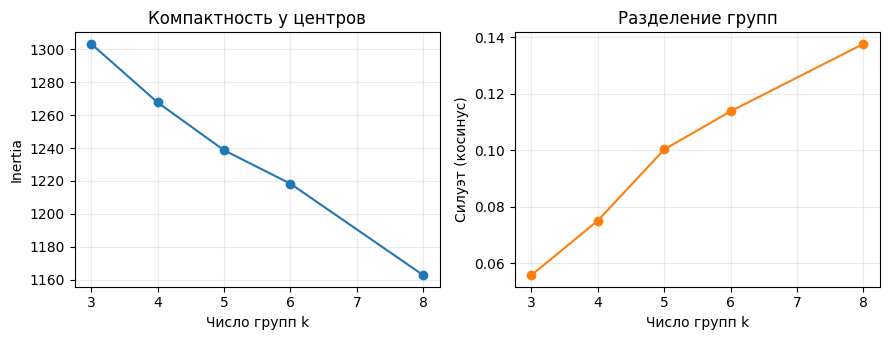

Выбранное k по силуэту: 8


In [21]:
# Шаг М3.04.21 — График внутренних показателей
best_k = int(cluster_table.loc[cluster_table['silhouette cosine'].idxmax(), 'k'])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].plot(cluster_table['k'], cluster_table['inertia'], marker='o')
axes[0].set(xlabel='Число групп k', ylabel='Inertia', title='Компактность у центров')
axes[1].plot(cluster_table['k'], cluster_table['silhouette cosine'], marker='o', color='tab:orange')
axes[1].set(xlabel='Число групп k', ylabel='Силуэт (косинус)', title='Разделение групп')
for ax in axes:
    ax.grid(alpha=.25)
plt.tight_layout()
plt.show()
print('Выбранное k по силуэту:', best_k)

**Итоговые назначения и размеры групп**

Итоговый K-means обучается с зафиксированным `best_k` и несколькими инициализациями. Выводятся размеры групп, число итераций и inertia. Слишком маленькая или почти всеобъемлющая группа потребовала бы отдельного разбора. Одни лишь сбалансированные размеры не доказывают полезность кластеризации, но помогают заметить технические странности результата.

In [22]:
# Шаг М3.04.22 — Итоговые назначения и размеры групп
with threadpool_limits(limits=2):
    km = KMeans(n_clusters=best_k, n_init=10, max_iter=150, random_state=17).fit(X)
cluster_ids = km.labels_
print('Итераций:', km.n_iter_, '| inertia:', round(km.inertia_, 2))
print(pd.Series(cluster_ids, name='кластер').value_counts().sort_index().to_string())

Итераций: 8 | inertia: 1162.83
кластер
0    239
1    445
2    309
3     86
4    238
5     45
6     45
7     45


**Пакетный вариант MiniBatchKMeans**

MiniBatchKMeans обновляет центры на небольших пакетах строк. Это бывает полезно на более крупных корпусах, но приближение может дать другое разбиение и другой показатель компактности. Здесь он обучается на тех же признаках и с тем же `k`; затем сравниваются размеры групп. Для небольшого учебного набора обычный K-means остаётся вполне достаточным.

In [23]:
# Шаг М3.04.23 — Пакетный вариант MiniBatchKMeans
with threadpool_limits(limits=2):
    mini = MiniBatchKMeans(n_clusters=best_k, batch_size=128, n_init=3, random_state=17).fit(X)
print('MiniBatch inertia:', round(mini.inertia_, 2))
print(pd.Series(mini.labels_, name='кластер').value_counts().sort_index().to_string())

MiniBatch inertia: 1179.11
кластер
0    252
1    312
2    251
3    164
4     45
5     82
6    301
7     45


**Слова центров и примеры сообщений**

Для каждого центра выводятся признаки с наибольшими весами и два ближайших по евклидовому расстоянию документа. Слова помогают дать группе рабочее описание, а документы проверяют контекст. Частые общие слова могут встретиться у нескольких центров; поэтому нельзя присвоить каждому кластеру название только по одному слову. Это исследовательская интерпретация, а не готовая разметка.

In [24]:
# Шаг М3.04.24 — Слова центров и примеры сообщений
feature_names = vectorizer.get_feature_names_out()
for cluster_no, center in enumerate(km.cluster_centers_):
    words = feature_names[np.argsort(center)[-8:][::-1]]
    members = np.flatnonzero(cluster_ids == cluster_no)
    distances = (np.asarray(X[members].multiply(X[members]).sum(axis=1)).ravel()
                 + float(center @ center) - 2 * np.asarray(X[members] @ center).ravel())
    closest = members[np.argsort(distances)[:2]]
    print(f'\nКластер {cluster_no}, документов {len(members)}; слова:', ', '.join(words))
    for i in closest:
        print(' ', train.loc[i, 'case_id'], '|', train.loc[i, 'clean_text'][:150])


Кластер 0, документов 239; слова: моему обращению, моему, по моему, информация по, номер нужна, информация, нужна информация, обращению
  доставка_07_023 | вопрос по заказу: прошу уточнить маршрут и дату получения заказа. заказ no номер . нужна информация по моему обращению.
  доставка_07_003 | вопрос по заказу: прошу уточнить маршрут и дату получения заказа. заказ no номер . нужна информация по моему обращению.

Кластер 1, документов 445; слова: номер жду, жду, жду уточнения, уточнения, не, на, день, добрый
  доставка_08_018 | вопрос по заказу: уведомление о прибытии есть, но курьера не было. заказ no номер . жду уточнения.
  доставка_08_030 | вопрос по заказу: уведомление о прибытии есть, но курьера не было. заказ no номер . жду уточнения.

Кластер 2, документов 309; слова: номер спасибо, помощь, за помощь, спасибо за, спасибо, за, не, день
  доставка_05_004 | не могу согласовать время приезда курьера. заказ no номер . спасибо за помощь.
  доставка_11_009 | перевозчик не нашёл адрес

**Темы как внешняя диагностика**

Только после фиксации модели колонка `topic` используется для таблицы пересечений с кластерами. Строка показывает состав одного найденного кластера по заранее известным широким темам. Совпадение может быть частичным: четыре темы не обязаны соответствовать выбранному `k`, а внутри темы существуют разные сюжеты. Таблица не использовалась ни для обучения, ни для выбора числа групп.

In [25]:
# Шаг М3.04.25 — Темы как внешняя диагностика
topic_table = pd.crosstab(pd.Series(cluster_ids, name='кластер'), train['topic'])
print(topic_table.to_string())
print('\nДоли тем внутри групп:')
print(topic_table.div(topic_table.sum(axis=1), axis=0).round(2).to_string())

topic    возврат  доставка  оплата  товар
кластер                                  
0             48        82      53     56
1             93       135     123     94
2             53       109      68     79
3              0         0      60     26
4             46        79      56     57
5              0        45       0      0
6              0        45       0      0
7              0        45       0      0

Доли тем внутри групп:
topic    возврат  доставка  оплата  товар
кластер                                  
0           0.20      0.34    0.22   0.23
1           0.21      0.30    0.28   0.21
2           0.17      0.35    0.22   0.26
3           0.00      0.00    0.70   0.30
4           0.19      0.33    0.24   0.24
5           0.00      1.00    0.00   0.00
6           0.00      1.00    0.00   0.00
7           0.00      1.00    0.00   0.00


**ARI после фиксации модели**

Adjusted Rand Index сравнивает два разбиения на пары документов и корректирует случайное совпадение. Его значение не зависит от числовых имён кластеров: перестановка номеров даёт тот же результат. ARI вычисляется один раз как внешняя диагностическая величина после выбора модели. Он сравнивает с широкими темами, а не доказывает, что найденные группы имеют единственно правильный смысл.

In [26]:
# Шаг М3.04.26 — ARI после фиксации модели
ari = adjusted_rand_score(train['topic'], cluster_ids)
renamed = np.array([best_k - 1 - x for x in cluster_ids])
print('ARI с широкими темами:', round(ari, 3))
print('ARI после перестановки номеров:', round(adjusted_rand_score(train['topic'], renamed), 3))

ARI с широкими темами: 0.002
ARI после перестановки номеров: 0.002


Группы построены без меток тем; число `k` выбрано по внутренней геометрической диагностике. Слова центров и примеры позволяют читать результат, а таблица тем и ARI дают ограниченную внешнюю проверку. Далее размерность уменьшается для компактного представления и наглядного рисунка.

## 5. LSA, проекция и границы интерпретации

TruncatedSVD строит низкоразмерное линейное представление разреженной матрицы без её центрирования и без превращения всего корпуса в плотный массив. Вход остаётся sparse, выход на 30 координат становится небольшим плотным массивом. Такое представление иногда называют LSA. При сравнении косинусом после SVD строки нужно снова нормировать. Доля объяснённой дисперсии описывает сохранённую вариацию данных, но не измеряет «правильность смысла» или качество поиска.

**Тридцать компонент из разреженной матрицы**

Строится представление с 30 компонентами. `TruncatedSVD` получает исходный sparse `X` и выдаёт небольшой плотный массив размера 1452×30. Выводятся форма и тип входа и выхода, а также доля объяснённой дисперсии. Эта доля показывает, какая вариация матрицы отражена выбранными компонентами; она не является оценкой тематической точности кластеров.

In [27]:
# Шаг М3.04.27 — Тридцать компонент из разреженной матрицы
svd = TruncatedSVD(n_components=30, random_state=17)
Z_raw = svd.fit_transform(X)
print('Вход:', type(X).__name__, X.shape)
print('Выход:', type(Z_raw).__name__, Z_raw.shape)
print('Суммарная объяснённая дисперсия:', round(float(svd.explained_variance_ratio_.sum()), 3))

Вход: csr_matrix (1452, 719)
Выход: ndarray (1452, 30)
Суммарная объяснённая дисперсия: 0.622


**Повторная нормировка и знак косинуса**

После SVD координаты уже могут быть отрицательными, и длины строк не обязаны равняться единице. Перед косинусным сравнением строки повторно нормируются. Рядом показан пример с противоположными направлениями: его косинус равен −1. Для исходных неотрицательных TF–IDF-векторов отрицательный косинус невозможен; после SVD теоретический диапазон шире.

In [28]:
# Шаг М3.04.28 — Повторная нормировка и знак косинуса
Z = normalize(Z_raw)
print('Нормы первых строк после SVD:', np.round(np.linalg.norm(Z[:3], axis=1), 3))
signed_example = cosine_similarity([[1., -1.]], [[-1., 1.]])[0, 0]
print('Косинус противоположных направлений:', round(float(signed_example), 3))
print('Минимальная координата SVD:', round(float(Z_raw.min()), 3))

Нормы первых строк после SVD: [1. 1. 1.]
Косинус противоположных направлений: -1.0
Минимальная координата SVD: -0.511


**Поиск в сжатом пространстве**

Тот же запрос проецируется обученным векторизатором и SVD, затем нормируется. Верхняя пятёрка сравнивается с исходным лексическим поиском. Разные ранги возможны: 30 координат теряют часть подробностей и смешивают совместно встречающиеся слова. Один пример не позволяет объявить какую-либо выдачу лучшей; для этого нужна отдельная оценка по запросам.

In [29]:
# Шаг М3.04.29 — Поиск в сжатом пространстве
compare_query = 'курьер перенёс доставку'
q_sparse = vectorizer.transform([normalize_text(compare_query)])
q_low = normalize(svd.transform(q_sparse))
low_scores = (Z @ q_low.T).ravel()
low_order = sorted(range(len(train)), key=lambda i: (-low_scores[i], train.loc[i, 'case_id']))[:5]
print('Исходный поиск:', search(compare_query, 5)[1]['case_id'].tolist())
print('После SVD:', [(train.loc[i, 'case_id'], round(float(low_scores[i]), 3)) for i in low_order])

Исходный поиск: ['доставка_00_005', 'доставка_00_043', 'доставка_00_019', 'доставка_00_034', 'доставка_00_030']
После SVD: [('доставка_00_005', 0.994), ('доставка_00_030', 0.994), ('доставка_00_013', 0.987), ('доставка_00_023', 0.987), ('доставка_00_001', 0.951)]


**Двумерная иллюстрация готовых кластеров**

Отдельный SVD переводит исходные векторы в две координаты только для рисунка. Цвета взяты из ранее обученного K-means на полной TF–IDF-матрице. Поэтому картинка показывает проекцию готового решения, а не процедуру получения этих групп. Пересечение цветов на плоскости не обязано означать отсутствие разделения в исходном пространстве; большая часть измерений здесь отброшена.

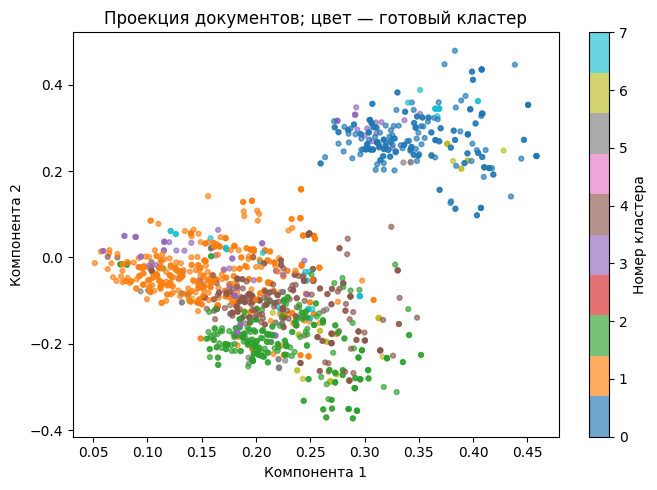

Доля дисперсии двух компонент: 0.04


In [30]:
# Шаг М3.04.30 — Двумерная иллюстрация готовых кластеров
svd2 = TruncatedSVD(n_components=2, random_state=17)
xy = svd2.fit_transform(X)
fig, ax = plt.subplots(figsize=(7, 5))
scatter = ax.scatter(xy[:, 0], xy[:, 1], c=cluster_ids, cmap='tab10', s=12, alpha=.65)
ax.set(xlabel='Компонента 1', ylabel='Компонента 2', title='Проекция документов; цвет — готовый кластер')
fig.colorbar(scatter, ax=ax, label='Номер кластера')
plt.tight_layout()
plt.show()
print('Доля дисперсии двух компонент:', round(float(svd2.explained_variance_ratio_.sum()), 3))

**Контрпример: случайно перемешанные отзывы**

Используются первые 300 строк `reviews.txt`; исходный файл не меняется. Это синтетические строки из небольшого набора перемешанных слов без меток и устойчивой тематической структуры. K-means всё равно обязан назначить каждой строке кластер; напечатанные слова центров не дают права придумывать тональность или реальные темы. Форма результата и примеры позволяют различить математическое разбиение и содержательное открытие.

In [31]:
# Шаг М3.04.31 — Контрпример: случайно перемешанные отзывы
reviews_path = Path('../../data/reviews.txt')
assert reviews_path.exists(), f'Не найден файл {reviews_path.resolve()}'
with reviews_path.open(encoding='utf-8') as stream:
    review_lines = [normalize_text(line) for line in islice(stream, 300)]
review_vectorizer = TfidfVectorizer()
R = review_vectorizer.fit_transform(review_lines)
with threadpool_limits(limits=2):
    review_model = KMeans(n_clusters=4, n_init=5, random_state=17).fit(R)
review_words = review_vectorizer.get_feature_names_out()
print('Строк:', len(review_lines), '| словарь:', len(review_words), '| размеры групп:', np.bincount(review_model.labels_).tolist())
for i, center in enumerate(review_model.cluster_centers_):
    print('Группа', i, '| ведущие слова:', ', '.join(review_words[np.argsort(center)[-5:][::-1]]))
print('Примеры строк:', review_lines[:2])

Строк: 300 | словарь: 20 | размеры групп: [87, 58, 96, 59]
Группа 0 | ведущие слова: отчёт, файл, клиент, блок, кластер
Группа 1 | ведущие слова: задача, ключ, товар, заказ, поиск
Группа 2 | ведущие слова: сумма, значение, город, узел, данные
Группа 3 | ведущие слова: сервер, запрос, кластер, данные, значение
Примеры строк: ['данные задача задача задача сервер таблица узел клиент товар узел лог значение ключ.', 'заказ данные поиск лог файл хранилище сумма значение блок город товар заказ узел.']


Сжатие дало небольшое плотное представление и двумерную иллюстрацию, но не изменило ранее выбранную процедуру группировки. Контрпример с синтетическими строками показывает: алгоритм всегда выдаёт номера групп, а содержательная интерпретация требует проверки данных и задачи.

## Полученный результат

Для 1452 уникальных учебных обращений получены разреженные TF–IDF-векторы, рассчитано косинусное сходство и реализован поиск с устойчивым порядком результатов. Пустые запросы и запросы без лексического сигнала не выдают произвольные документы. Для похожих обращений порог подобран только на маленьких валидационных парах и остаётся учебной иллюстрацией, а не правилом автоматического объединения клиентов.

Четыре запроса получили явные критерии релевантности; Precision@5 и MRR рассчитаны только внутри полностью размеченного пула из 12 документов. Группировка K-means выбирала число групп по внутреннему силуэту без меток тем; центры были прочитаны через слова и типичные сообщения, а темы и ARI использованы только после фиксации модели. SVD дал компактное представление и рисунок проекции готовых кластеров. Синтетические строки `reviews.txt` напомнили, что математическое разбиение не обязано совпадать с содержательной тематикой.

## Документация

[Косинусное сходство в scikit-learn](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html)

[KMeans в scikit-learn](https://scikit-learn.org/1.8/modules/generated/sklearn.cluster.KMeans.html)

[MiniBatchKMeans в scikit-learn](https://scikit-learn.org/1.8/modules/generated/sklearn.cluster.MiniBatchKMeans.html)

[TruncatedSVD в scikit-learn](https://scikit-learn.org/1.8/modules/generated/sklearn.decomposition.TruncatedSVD.html)

[Silhouette в scikit-learn](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.silhouette_score.html)